In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import random
from src.data.io_utils import read_tif_image, convert_image_to_array

In [2]:
images_patches = Path("/mnt/x/donnees/pachs_64_2classes_slices40/images")
masks_patches = Path("/mnt/x/donnees/pachs_64_2classes_slices40/masks")

print(f"Images existent: {images_patches.exists()}")
print(f"Masks existent: {masks_patches.exists()}")

Images existent: True
Masks existent: True


In [3]:
image_files = sorted(images_patches.glob("*.tif"))
mask_files = sorted(masks_patches.glob("*.npy"))

print(f"Total patches: {len(image_files)}")
print(f"Total masks: {len(mask_files)}")

SAMPLE_SIZE = 2500
random.seed(42)
selected_indices = random.sample(range(len(image_files)), min(SAMPLE_SIZE, len(image_files)))

print(f"Patches sélectionnés: {len(selected_indices)}")

Total patches: 3509
Total masks: 3509
Patches sélectionnés: 2500


In [4]:
print("Analyse des classes...")
print("-" * 40)

total_voxels = 0
total_c0 = 0
total_c1 = 0

for i, idx in enumerate(selected_indices):
    mask_file = mask_files[idx]
    mask = np.load(mask_file)
    
    total_voxels += mask.size
    total_c0 += (mask == 0).sum()
    total_c1 += (mask == 1).sum()
    
    if (i + 1) % 500 == 0:
        print(f"  Analysé {i+1}/{len(selected_indices)} patches")

print(f"\n✅ Analyse terminée!")

Analyse des classes...
----------------------------------------
  Analysé 500/2500 patches
  Analysé 1000/2500 patches
  Analysé 1500/2500 patches
  Analysé 2000/2500 patches
  Analysé 2500/2500 patches

✅ Analyse terminée!


In [5]:
pct0 = (total_c0 / total_voxels) * 100
pct1 = (total_c1 / total_voxels) * 100

print("=" * 50)
print("RÉSULTATS - DISTRIBUTION DES CLASSES (2 CLASSES)")
print("=" * 50)
print(f"Patches analysés: {len(selected_indices):,}")
print(f"Total voxels: {total_voxels:,}")
print()
print(f"Classe 0 (Fond):        {pct0:.2f}%  ({total_c0:,} voxels)")
print(f"Classe 1 (Neurones):    {pct1:.4f}%  ({total_c1:,} voxels)")
print()
print(f"Ratio Fond/Neurones:     {total_c0/total_c1:.1f}")


RÉSULTATS - DISTRIBUTION DES CLASSES (2 CLASSES)
Patches analysés: 2,500
Total voxels: 655,360,000

Classe 0 (Fond):        97.80%  (640,938,773 voxels)
Classe 1 (Neurones):    2.2005%  (14,421,227 voxels)

Ratio Fond/Neurones:     44.4


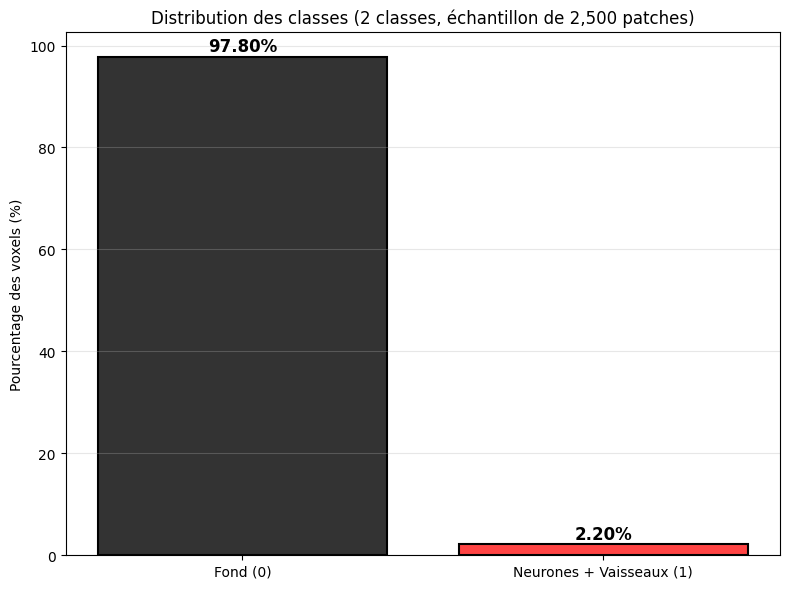

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

classes = ['Fond (0)', 'Neurones + Vaisseaux (1)']
percentages = [pct0, pct1]
colors = ['#333333', '#FF4444']

bars = ax.bar(classes, percentages, color=colors, edgecolor='black', linewidth=1.5)

for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{pct:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title(f'Distribution des classes (2 classes, échantillon de {len(selected_indices):,} patches)')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

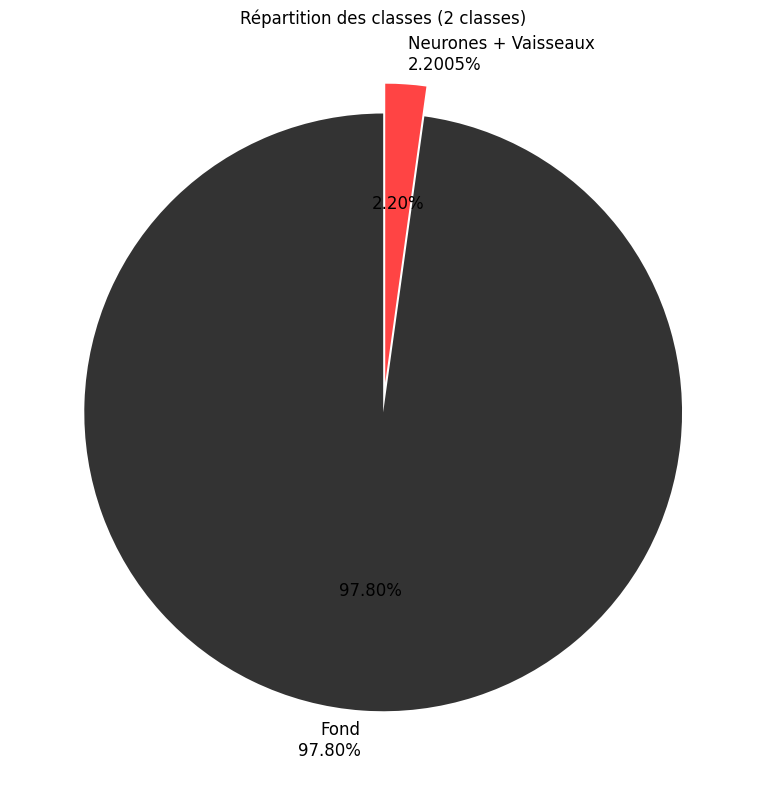

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))

labels = [f'Fond\n{pct0:.2f}%', f'Neurones + Vaisseaux\n{pct1:.4f}%']
colors = ['#333333', '#FF4444']
explode = (0.02, 0.08)

wedges, texts, autotexts = ax.pie(
    percentages, 
    labels=labels, 
    colors=colors, 
    explode=explode,
    autopct='%1.2f%%',
    startangle=90,
    textprops={'fontsize': 12}
)

ax.set_title(f'Répartition des classes (2 classes)')
plt.tight_layout()
plt.show()


In [8]:
def show_patch_2class(image_path, mask_path, slice_idx=None):
    image_sitk = read_tif_image(str(image_path))
    mask = np.load(mask_path)
    image = convert_image_to_array(image_sitk)
    
    if slice_idx is None:
        slice_idx = image.shape[0] // 2
    
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_slice = mask[slice_idx, :, :]
    
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f'Image - Slice {slice_idx}')
    axes[0].axis('off')
    
    axes[1].imshow(rgb_mask)
    axes[1].set_title('Mask 2 Classes')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title('Superposition (Neurones en rouge)')
    axes[2].axis('off')
    
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Fond (0)'),
        Patch(facecolor='red', label='Neurones (1)')
    ]
    axes[2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.suptitle(f'{image_path.name}')
    plt.tight_layout()
    plt.show()
    
    print(f"  Classe 0: {(mask == 0).sum():,}")
    print(f"  Classe 1: {(mask == 1).sum():,}")


VISUALISATION DE 10 PATCHES ALÉATOIRES


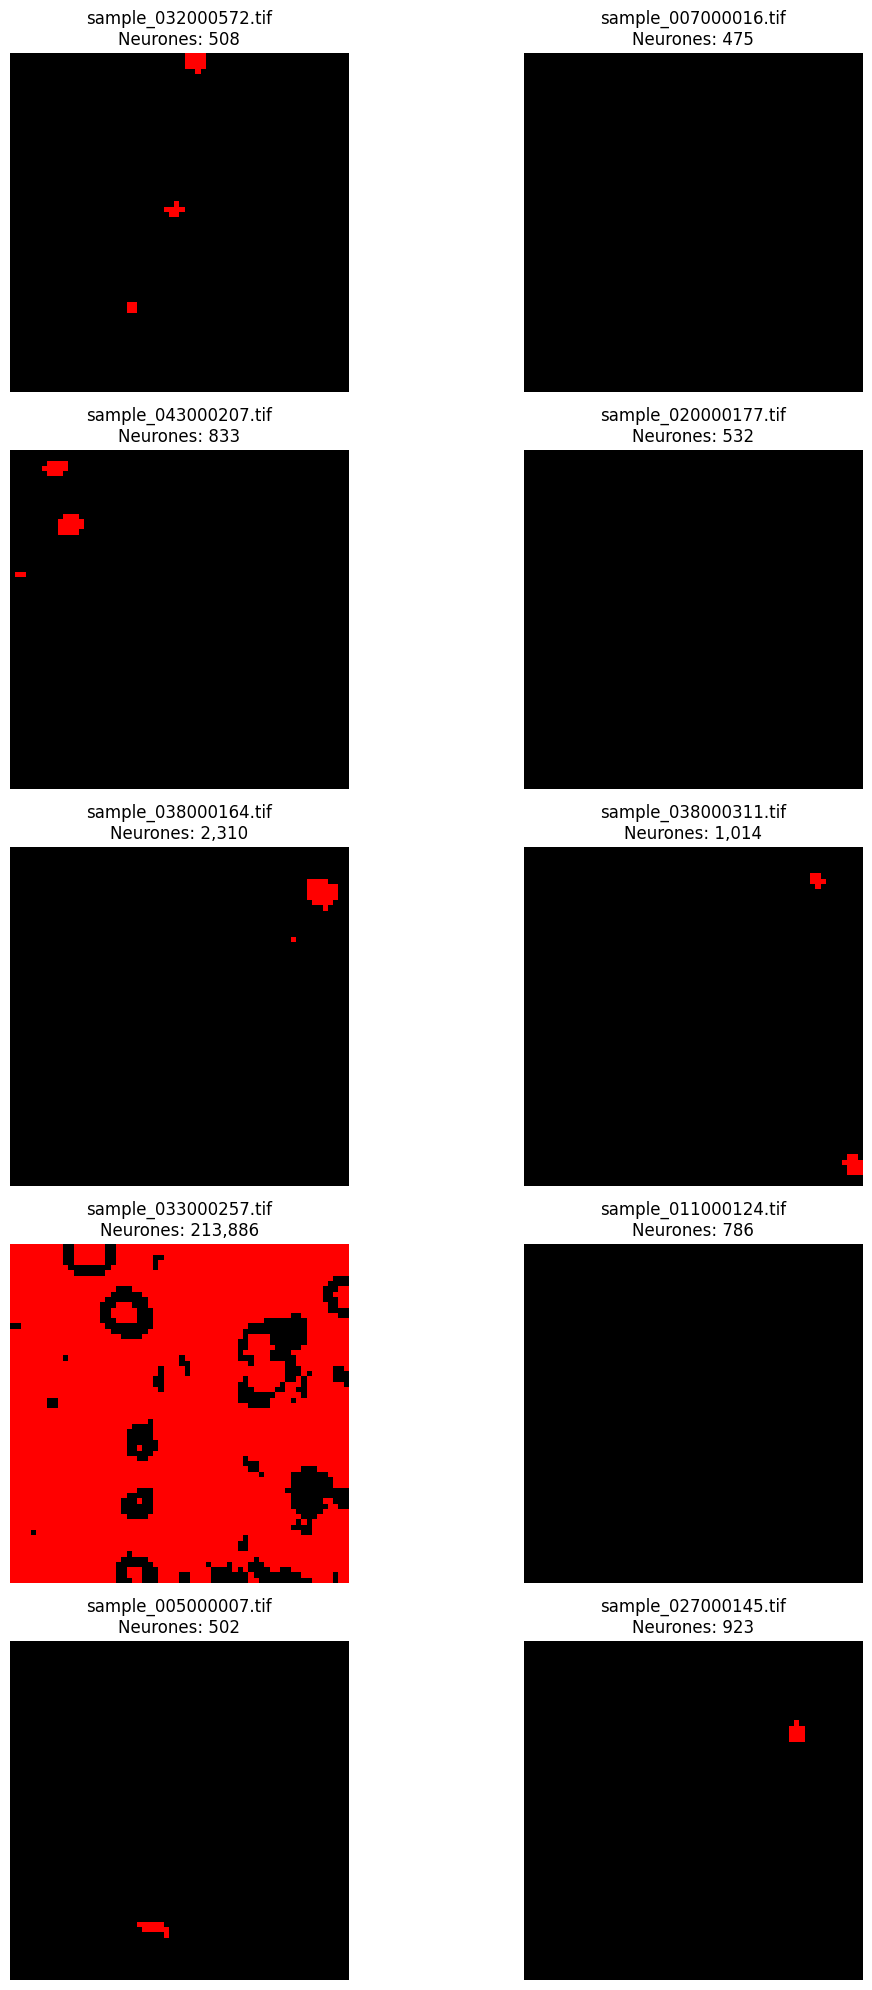

In [9]:
print("\n" + "=" * 50)
print("VISUALISATION DE 10 PATCHES ALÉATOIRES")
print("=" * 50)

random_indices = random.sample(selected_indices, min(10, len(selected_indices)))

# Grille 5x2
fig, axes = plt.subplots(5, 2, figsize=(12, 20))
axes = axes.flatten()

for i, idx in enumerate(random_indices):
    mask = np.load(mask_files[idx])
    slice_idx = mask.shape[0] // 2
    mask_slice = mask[slice_idx, :, :]
    
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    
    axes[i].imshow(rgb_mask)
    axes[i].set_title(f"{image_files[idx].name}\nNeurones: {(mask==1).sum():,}")
    axes[i].axis('off')

for j in range(len(random_indices), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()



VISUALISATION DE 10 PATCHES (IMAGE + MASK + SUPERPOSITION)


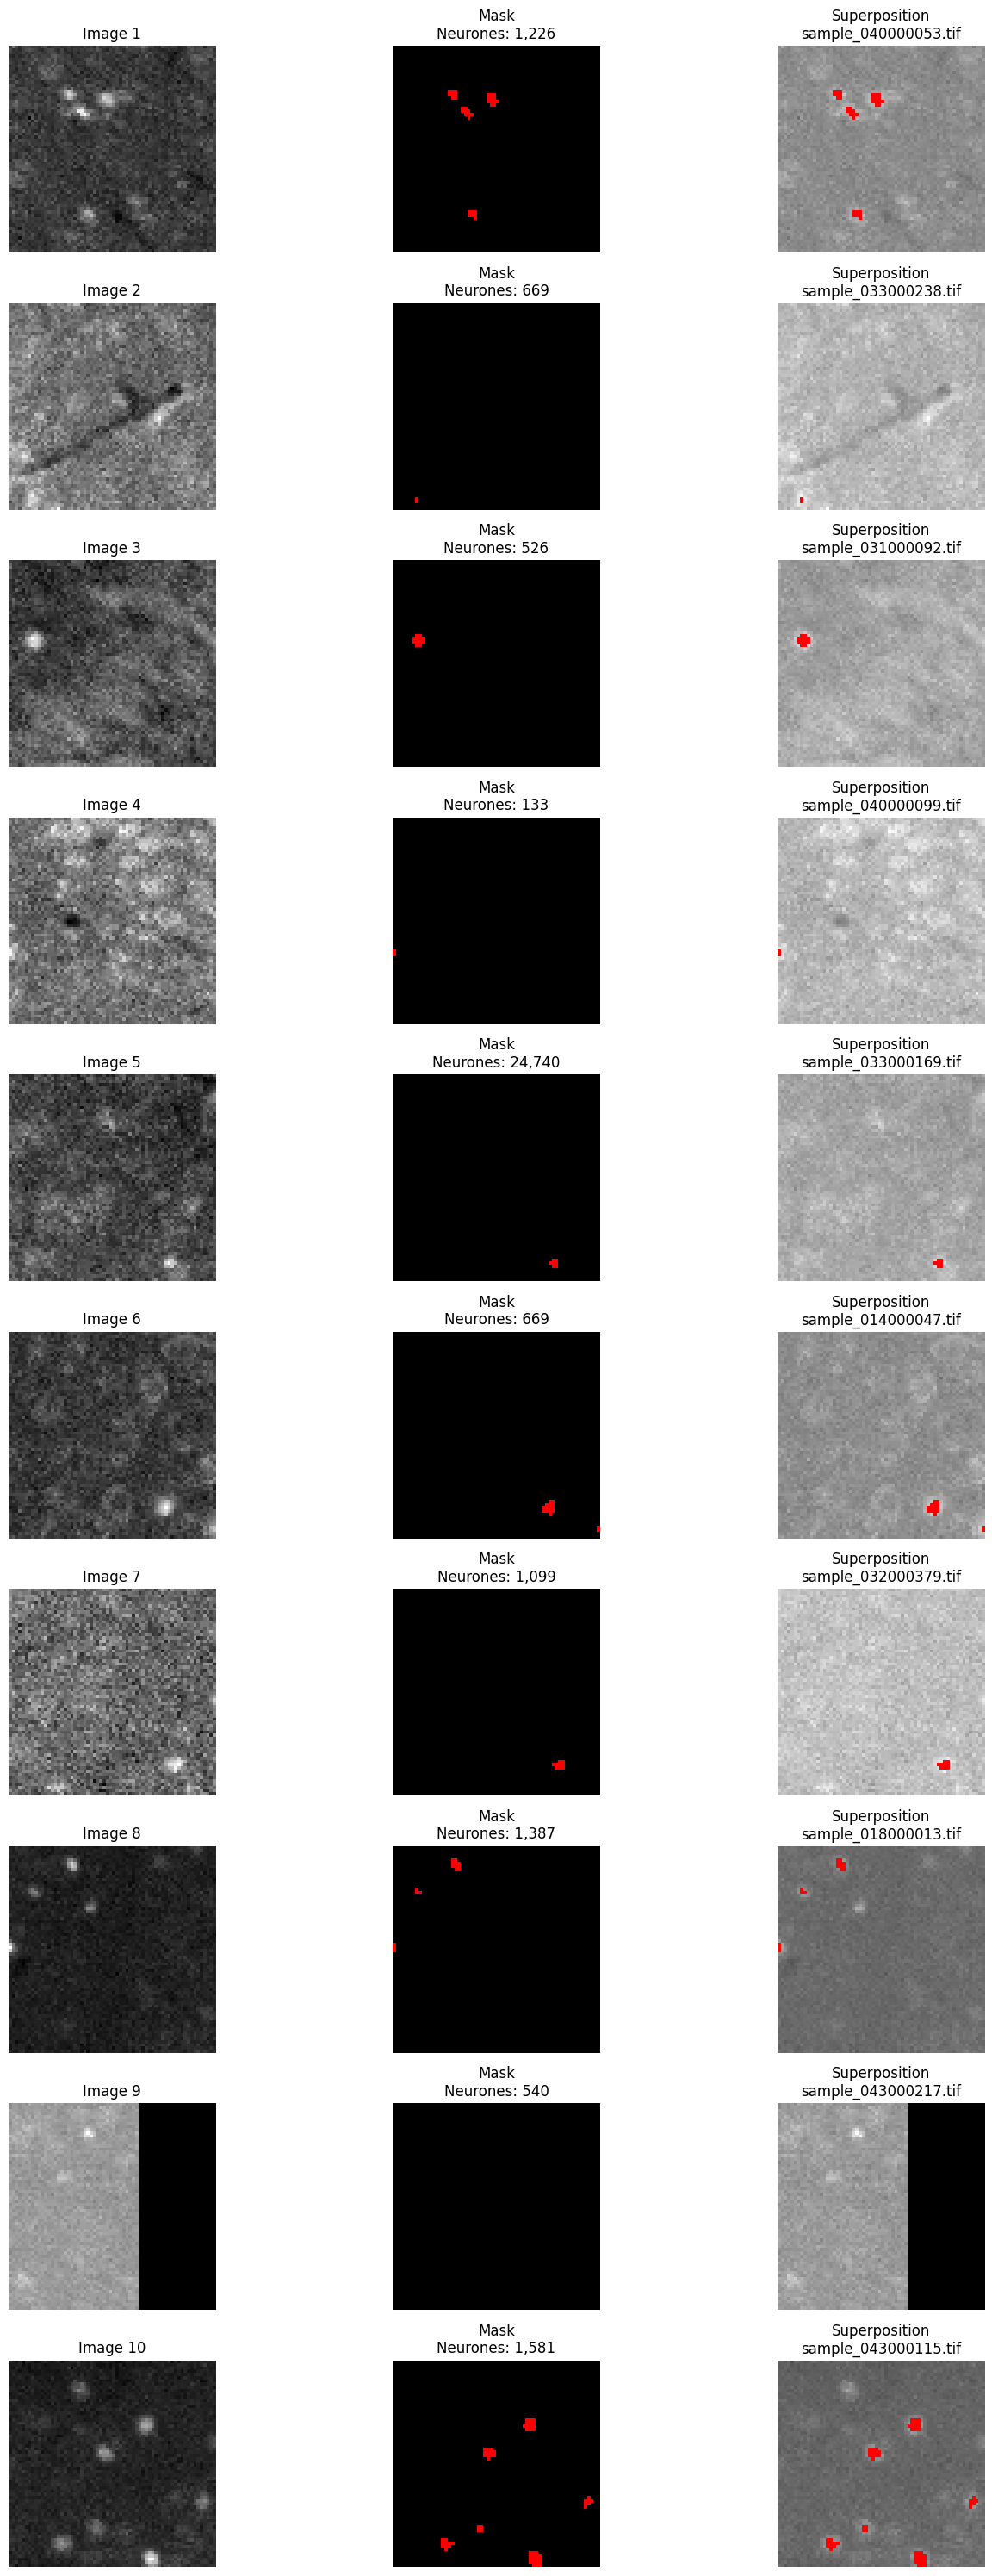

In [19]:

print("\n" + "=" * 50)
print("VISUALISATION DE 10 PATCHES (IMAGE + MASK + SUPERPOSITION)")
print("=" * 50)

random_indices = random.sample(selected_indices, min(10, len(selected_indices)))

fig, axes = plt.subplots(10, 3, figsize=(15, 30))

for i, idx in enumerate(random_indices):
    image_file = image_files[idx]
    mask_file = mask_files[idx]
    
    # Charger image et mask
    image_sitk = read_tif_image(str(image_file))
    image = convert_image_to_array(image_sitk)
    mask = np.load(mask_file)
    
    # Prendre la tranche du milieu
    slice_idx = image.shape[0] // 2
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    mask_slice = mask[slice_idx, :, :]
    
    # Image seule
    axes[i, 0].imshow(img_slice, cmap='gray')
    axes[i, 0].set_title(f'Image {i+1}')
    axes[i, 0].axis('off')
    
    # Mask (neurones en rouge)
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    axes[i, 1].imshow(rgb_mask)
    axes[i, 1].set_title(f'Mask\nNeurones: {(mask==1).sum():,}')
    axes[i, 1].axis('off')
    
    # Superposition (neurones en rouge sur l'image)
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(f'Superposition\n{image_file.name[:20]}')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()